<div style="
    background-color: #7BAFD4;
    border-radius: 18px;
    padding: 22px 26px;
    display: flex;
    align-items: center;
    gap: 24px;
    margin-bottom: 18px;
">
    <img src="592_avatar_lr.png" alt="GEOG 592"
        style="width:110px;height:110px;border-radius:22px;">
    <div>
        <div style="
            font-family: Impact, 'Arial Black', Arial, sans-serif;
            font-size: 42px;
            font-weight: 900;
            letter-spacing: 2px;
            line-height: 1;
            color: white;
        ">GEOG 592</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 22px;
            font-weight: 700;
            color: #13294B;
            margin-top: 8px;
        ">GIS Programming</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 16px;
            color: #13294B;
            margin-top: 6px;
        ">Cartography examples using GBIF and census data</div>
    </div>
</div>

## Charlotte Strom
## 10/21/26

# Research Question:

Both the Venus flytrap (Dionaea muscipula) and the Hooded pitcherplant (Sarracenia minor) are native carnivorous plants to North Carolina. The habitats which these plants thrive in is broadly considered wetlands, where there is wet, nutrient-poor soil, primarily in the coastal plain of North Carolina. Due to habitat destruction, attributed to the filling of wetlands for development, and the illegal poaching of the plants, the Venus flytrap and the Hooded pitcherplant are considered endangered. 

I want to explore how endangered carnivorous plants are affected by development and wetland loss in North Carolina through GBIF and species distribution data by creating four maps:

1. Distribution- Where is each species currently documented?

2. Overlap- Which counties have records of both species?

3. Historical records- Where are historical records documented?

4. Ecological- Do counties with documented occurrences of these two species also contain substantial wetland habitat?

# 1. Import Data 

In [2]:
# Loading Libraries
import time
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

In [3]:
### GBIF species occurrence data

species = ["Dionaea muscipula", "Sarracenia flava"]

api = "https://api.gbif.org/v1"
records = []

for name in species:

    # Find the GBIF taxon identifier
    response = requests.get(
        f"{api}/species/match",
        params={"name": name, "strict": "true"},
        timeout=60
    )
    response.raise_for_status()
    match = response.json()

    if match.get("rank") != "SPECIES":
        raise ValueError(f"Check the species name: {name}")

    taxon_key = match.get("acceptedUsageKey", match["usageKey"])

    # Define the occurrence search
    parameters = {
        "taxonKey": taxon_key,
        "country": "US",
        "stateProvince": "North Carolina",
        "occurrenceStatus": "PRESENT",
        "hasCoordinate": "true",
        "hasGeospatialIssue": "false",
        "limit": 300,
        "offset": 0
    }

    species_records = []

    while True:
        response = requests.get(
            f"{api}/occurrence/search",
            params=parameters,
            timeout=60
        )
        response.raise_for_status()
        page = response.json()

        if page["count"] > 9000:
            raise ValueError(
                f"{name} has too many records. "
                "Use a GBIF bulk download or narrow the search."
            )

        for record in page["results"]:
            record["queried_species"] = name

        species_records.extend(page["results"])

        if page.get("endOfRecords") or not page["results"]:
            break

        parameters["offset"] += len(page["results"])
        time.sleep(0.2)

    records.extend(species_records)

    print(f"{name}: {len(species_records):,} records")

Dionaea muscipula: 1,987 records
Sarracenia flava: 2,283 records


# 2. Select Important Columns

In [41]:
plants = pd.DataFrame(records)

plants = plants[
    [
        "queried_species",
        "decimalLongitude",
        "decimalLatitude",
        "year",
        "county",
        "basisOfRecord"
    ]
].copy()

plants

,queried_species,decimalLongitude,decimalLatitude,year,county,basisOfRecord
0,Dionaea muscipula,-78.289579,34.135403,2026.0,NaN,HUMAN_OBSERVATION
1,Dionaea muscipula,-78.242698,34.013463,2026.0,NaN,HUMAN_OBSERVATION
2,Dionaea muscipula,-77.829090,34.072463,2026.0,NaN,HUMAN_OBSERVATION
3,Dionaea muscipula,-76.903033,34.760041,2026.0,NaN,HUMAN_OBSERVATION
4,Dionaea muscipula,-78.391138,34.157217,2026.0,NaN,HUMAN_OBSERVATION
...,...,...,...,...,...,...
4265,Sarracenia flava,-80.000000,35.500000,NaN,NaN,PRESERVED_SPECIMEN
4266,Sarracenia flava,-80.000000,35.500000,NaN,NaN,PRESERVED_SPECIMEN
4267,Sarracenia flava,-78.638614,35.772096,NaN,Wake Co.,PRESERVED_SPECIMEN
4268,Sarracenia flava,-80.887296,35.782636,NaN,Iredell,PRESERVED_SPECIMEN


# 3. Create GeoDataFrame

In [5]:
plant_points = gpd.GeoDataFrame(
    plants.copy(),
    geometry=gpd.points_from_xy(
        plants["decimalLongitude"],
        plants["decimalLatitude"]
    ),
    crs="EPSG:4326"
)

# Project to a coordinate system suitable for North Carolina
plant_points = plant_points.to_crs(epsg=6543)

# Remove records outside North Carolina's state boundary
url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/"
url_state = "cb_2024_us_state_500k.zip"

states = gpd.read_file(url_0 + url_state)
nc_state = states.loc[states["STUSPS"] == "NC"].to_crs(epsg=6543)

plant_points = gpd.sjoin(
    plant_points,
    nc_state[["geometry"]],
    how="inner",
    predicate="within"
).drop(columns=["index_right"])

plant_points.head()

,queried_species,decimalLongitude,decimalLatitude,year,county,basisOfRecord,geometry
0,Dionaea muscipula,-78.289579,34.135403,2026.0,NaN,HUMAN_OBSERVATION,POINT (2214996.912 141041.677)
1,Dionaea muscipula,-78.242698,34.013463,2026.0,NaN,HUMAN_OBSERVATION,POINT (2229522.948 96767.534)
3,Dionaea muscipula,-76.903033,34.760041,2026.0,NaN,HUMAN_OBSERVATION,POINT (2629768.17 374252.09)
4,Dionaea muscipula,-78.391138,34.157217,2026.0,NaN,HUMAN_OBSERVATION,POINT (2184213.52 148776.442)
5,Dionaea muscipula,-78.380658,34.182564,2026.0,NaN,HUMAN_OBSERVATION,POINT (2187326.69 158020.813)


# 4. Load County Boundaries

In [8]:
# Load North Carolina county shapefile
nc_counties = gpd.read_file("/Users/Charlotte/Desktop/SeniorYear/GEOG_592/geog592-stromc/geog592-stromc/homework/Week09/North_Carolina_State_and_County_Boundary_Polygons.geojson",
                            encoding='Latin1')

# Check the columns and coordinate system
print(nc_counties.columns.tolist())
print(nc_counties.crs)

['OBJECTID', 'County', 'FIPS', 'Rec_Survey', 'NCGS_url', 'ck_date', 'Shape__Area', 'Shape__Length', 'GlobalID', 'geometry']
EPSG:4326


In [23]:
# Reproject to match the species points
nc_counties = nc_counties.to_crs(epsg=6543)

# Check the county names
nc_counties.head()

print(nc_counties.crs)
nc_counties

EPSG:6543


,OBJECTID,County,FIPS,Rec_Survey,NCGS_url,ck_date,Shape__Area,Shape__Length,GlobalID,geometry
0,1,Alamance,001,Recorded survey data is available. Visit North...,https://ncem-gis.maps.arcgis.com/apps/webappvi...,2025-01-13 00:00:00+00:00,1.210717e+10,476733.362073,acd66e2b-e702-4b3a-82c1-eb86e12d3804,"POLYGON ((1923604.345 881802.091, 1923341.195 ..."
1,2,Alexander,003,Recorded survey data is available. Visit North...,https://ncem-gis.maps.arcgis.com/apps/webappvi...,2025-01-13 00:00:00+00:00,7.343450e+09,387342.137292,6a1dac25-2574-4182-b77b-0074a5482dac,"POLYGON ((1374326.862 744227.342, 1374262.766 ..."
2,3,Alleghany,005,No recent survey data available,,2011-11-29 00:00:00+00:00,6.576362e+09,439166.717185,d8e726fa-ac7d-4212-a981-6ea0b111cee0,"POLYGON ((1336457.551 959892.73, 1336578.943 9..."
3,4,Anson,007,No recent survey data available,,2011-11-29 00:00:00+00:00,1.497020e+10,575503.754866,e4518706-732a-4abe-9079-9de6523b4747,"POLYGON ((1618558.995 528615.286, 1618623 5286..."
4,5,Ashe,009,Recorded survey data is available. Visit North...,https://ncem-gis.maps.arcgis.com/apps/webappvi...,2025-01-13 00:00:00+00:00,1.193926e+10,520084.244333,6d39c7ea-b7f4-4ac8-be47-65dfe4a46074,"POLYGON ((1269470.886 915478.909, 1266824.855 ..."
...,...,...,...,...,...,...,...,...,...,...
95,96,Wayne,191,Recorded survey data is available. Visit North...,https://ncem-gis.maps.arcgis.com/apps/webappvi...,2025-01-13 00:00:00+00:00,1.554411e+10,579779.305793,d8af9501-60d9-48eb-95b0-fe5d25bfa0c2,"POLYGON ((2297704.655 669585.811, 2297802.27 6..."
96,97,Wilkes,193,Recorded survey data is available. Visit North...,https://ncem-gis.maps.arcgis.com/apps/webappvi...,2025-01-13 00:00:00+00:00,2.111152e+10,718180.039408,69241b1a-84e3-4fa4-8b2e-197d151c8dbe,"POLYGON ((1319003.919 828582.081, 1318920.299 ..."
97,98,Wilson,195,Recorded survey data is available. Visit North...,https://ncem-gis.maps.arcgis.com/apps/webappvi...,2025-01-13 00:00:00+00:00,1.039961e+10,430628.770432,2b485dcd-086d-441f-9e9c-c33b82b18800,"POLYGON ((2350081.935 670058.039, 2349948.507 ..."
98,99,Yadkin,197,Recorded survey data is available. Visit North...,https://ncem-gis.maps.arcgis.com/apps/webappvi...,2025-01-13 00:00:00+00:00,9.415514e+09,452687.390790,1434800b-c873-4475-8865-cea54663d8f2,"POLYGON ((1557884.733 838963.611, 1557598.265 ..."


# 5. Map 1: Distribution of Both Species

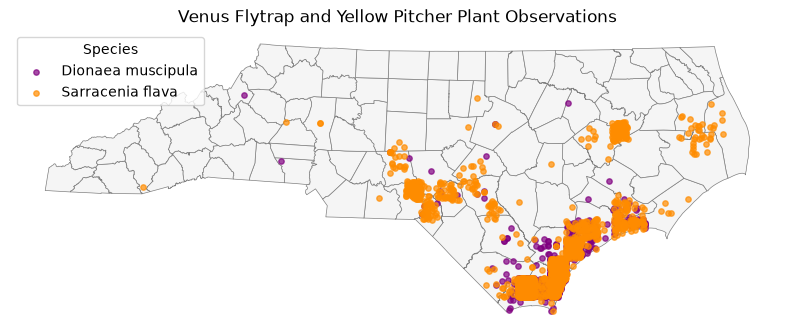

In [11]:
def pointMap(ax):

    nc_counties.plot(
        ax=ax,
        facecolor="whitesmoke",
        edgecolor="gray",
        linewidth=0.5
    )

    colors = {
        "Dionaea muscipula": "purple",
        "Sarracenia flava": "darkorange"
    }

    for name, color in colors.items():
        plant_points.loc[
            plant_points["queried_species"] == name
        ].plot(
            ax=ax,
            color=color,
            markersize=15,
            alpha=0.7,
            label=name
        )

    ax.set_title("Venus Flytrap and Yellow Pitcher Plant Observations")
    ax.legend(title="Species")
    ax.set_axis_off()

    return ax


fig, ax = plt.subplots(figsize=(10, 8))
pointMap(ax)
plt.show()

# 6. Prepare County-Level Observation Counts

    County-level observation counts is needed for the next three maps.

In [12]:
points_by_county = gpd.sjoin(
    plant_points,
    nc_counties[["County", "geometry"]],
    how="inner",
    predicate="within"
).drop(columns=["index_right"])

counts = (
    points_by_county
    .groupby(["County", "queried_species"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        columns=["Dionaea muscipula", "Sarracenia flava"],
        fill_value=0
    )
)

counts.head()

queried_species,Dionaea muscipula,Sarracenia flava
County,,
Anson,0,1
Avery,1,0
Beaufort,0,35
Bladen,5,7
Brunswick,1002,976


# 7. Map 2: County-level Observations

    Note that the GBIF dataset contains only recorded observations. It does not represent actual plant population density.

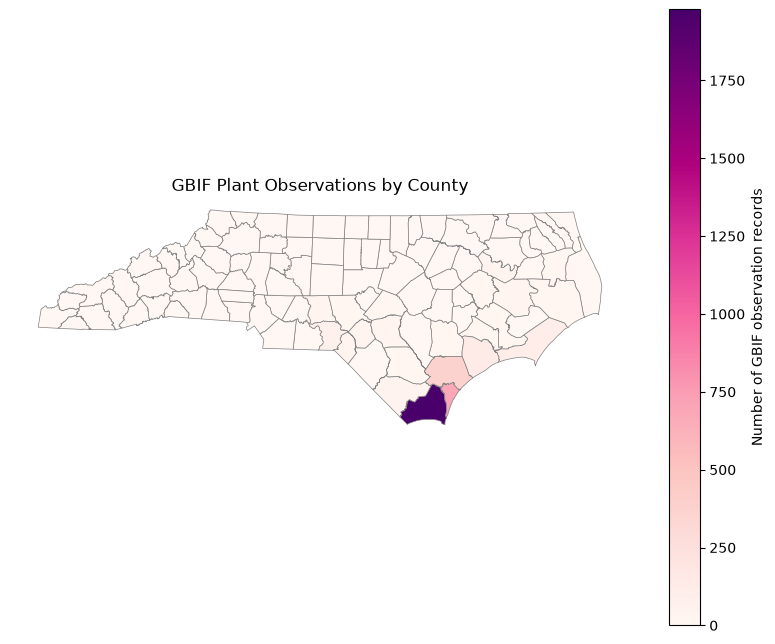

In [13]:
def countyCountMap(ax, nc_counties, counts):

    county_map = nc_counties.merge(
        counts,
        left_on="County",
        right_index=True,
        how="left"
    )

    species_columns = [
        "Dionaea muscipula",
        "Sarracenia flava"
    ]

    county_map[species_columns] = (
        county_map[species_columns].fillna(0)
    )

    county_map["total"] = county_map[species_columns].sum(axis=1)

    county_map.plot(
        column="total",
        cmap="RdPu",
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={
            "label": "Number of GBIF observation records"
        },
        ax=ax
    )

    ax.set_title("GBIF Plant Observations by County")
    ax.set_axis_off()

    return ax


fig, ax = plt.subplots(figsize=(10, 8))
countyCountMap(ax, nc_counties, counts)
plt.show()

# 8. Map 3: Where do the two species overlap

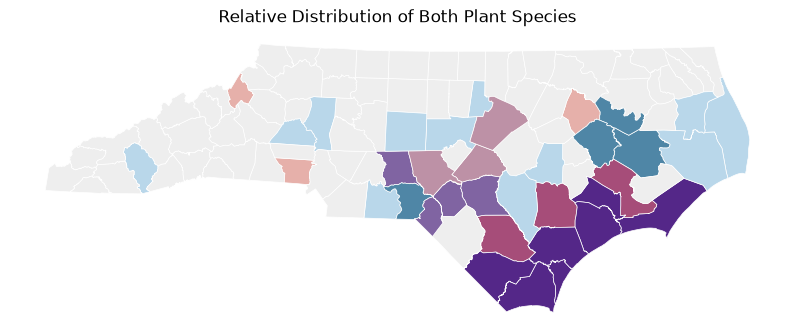

In [16]:
def overlapMap(ax, nc_counties, counts):

    bivariate = nc_counties.merge(
        counts,
        left_on="County",
        right_index=True,
        how="left"
    )

    species_columns = [
        "Dionaea muscipula",
        "Sarracenia flava"
    ]

    bivariate[species_columns] = (
        bivariate[species_columns].fillna(0)
    )

    for name in species_columns:
        values = bivariate[name]
        positive = values[values > 0]

        median = positive.median() if len(positive) else 0

        bivariate[name + "_class"] = np.select(
            [
                values == 0,
                (values > 0) & (values <= median)
            ],
            [0, 1],
            default=2
        )

    # Rows = Venus flytrap; columns = yellow pitcher plant
    palette = np.array([
        ["#eeeeee", "#b9d7ea", "#4f86a6"],
        ["#e6b0aa", "#bd91a6", "#8064a2"],
        ["#c0392b", "#a64d79", "#542788"]
    ])

    bivariate["color"] = [
        palette[venus, pitcher]
        for venus, pitcher in zip(
            bivariate["Dionaea muscipula_class"],
            bivariate["Sarracenia flava_class"]
        )
    ]

    bivariate.plot(
        color=bivariate["color"],
        edgecolor="white",
        linewidth=0.5,
        ax=ax
    )

    legend = True

    ax.set_title("Relative Distribution of Both Plant Species")
    ax.set_axis_off()

    return ax


fig, ax = plt.subplots(figsize=(10, 8))
overlapMap(ax, nc_counties, counts)
plt.show()

# 9. Map 4: Species Observations and Wetlands

/Users/Charlotte/Desktop/SeniorYear/GEOG_592/geog592-stromc/geog592-stromc/.venv/lib/python3.14/site-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'NC_geopackage_wetlands.gpkg': 'NC_Wetlands_Historic_Map_Info' (default), 'North_Carolina', 'NC_Wetlands', 'NC_Wetlands_Project_Metadata'. Specify layer parameter to avoid this warning.
  result = read_func(


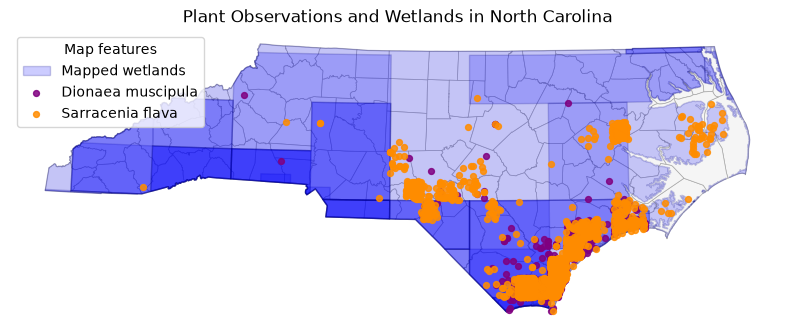

In [18]:
wetlands = gpd.read_file("/Users/Charlotte/Desktop/SeniorYear/GEOG_592/geog592-stromc/geog592-stromc/homework/Week09/NC_geopackage_wetlands.gpkg")

# Match the coordinate system of the county and point layers
wetlands = wetlands.to_crs(nc_counties.crs)

# Keep wetlands within North Carolina
wetlands = gpd.clip(wetlands, nc_state)


def wetlandMap(ax):

    nc_counties.plot(
        ax=ax,
        facecolor="whitesmoke",
        edgecolor="darkgray",
        linewidth=0.5
    )

    wetlands.plot(
        ax=ax,
        color="blue",
        edgecolor="navy",
        alpha=0.2,
        label="Mapped wetlands"
    )

    colors = {
        "Dionaea muscipula": "purple",
        "Sarracenia flava": "darkorange"
    }

    for name, color in colors.items():
        plant_points.loc[
            plant_points["queried_species"] == name
        ].plot(
            ax=ax,
            color=color,
            markersize=18,
            alpha=0.85,
            label=name
        )

    ax.set_title("Plant Observations and Wetlands in North Carolina")
    ax.legend(title="Map features")
    ax.set_axis_off()

    return ax


fig, ax = plt.subplots(figsize=(10, 8))
wetlandMap(ax)
plt.show()

# 10. Proportional Symbol Map

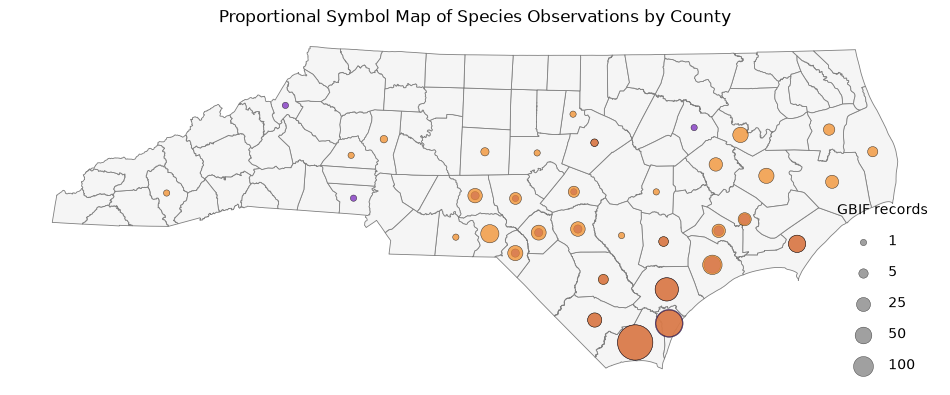

In [28]:
species_columns = ["Dionaea muscipula", "Sarracenia flava"]

county_map = nc_counties.merge(
    counts,
    left_on="County",
    right_index=True,
    how="left"
)

for col in species_columns:
    county_map[col] = county_map[col].fillna(0).astype(int)

county_map = county_map.to_crs(epsg=6543)
county_map["centroid"] = county_map.geometry.centroid

colors = {
    "Dionaea muscipula": "#7b2cbf",
    "Sarracenia flava": "#f28e2b"
}

fig, ax = plt.subplots(figsize=(12, 10))

# Base county map
nc_counties.to_crs(epsg=6543).plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="gray",
    linewidth=0.6
)

# Scale symbols by the maximum county count across both species
max_count = county_map[species_columns].max().max()
size_scale = 650

for species, color in colors.items():
    species_data = county_map.loc[county_map[species] > 0, ["County", species, "centroid"]].copy()
    if species_data.empty:
        continue

    species_data["x"] = species_data["centroid"].x
    species_data["y"] = species_data["centroid"].y

    symbol_size = np.sqrt(species_data[species] / max_count) * size_scale

    ax.scatter(
        species_data["x"],
        species_data["y"],
        s=symbol_size,
        c=color,
        alpha=0.75,
        edgecolors="black",
        linewidths=0.35,
        label=species
    )

ax.set_title("Proportional Symbol Map of Species Observations by County")
ax.set_axis_off()

# Size legend
legend_values = [1, 5, 25, 50, 100]
legend_sizes = np.sqrt(np.array(legend_values) / max_count) * size_scale

handles = [
    plt.scatter(
        [], [], s=s, c="gray", alpha=0.75,
        edgecolors="black", linewidths=0.3
    )
    for s in legend_sizes
]

ax.legend(
    handles,
    [str(v) for v in legend_values],
    title="GBIF records",
    scatterpoints=1,
    frameon=False,
    loc="lower right",
    labelspacing=1.2
)

plt.show()

# 11. Hexagon Map 


In [40]:
from shapely.geometry import Polygon

species_columns = ["Dionaea muscipula", "Sarracenia flava"]

county_map = nc_counties.merge(
    counts,
    left_on="County",
    right_index=True,
    how="left"
)

county_map.fillna("-")

,OBJECTID,County,FIPS,Rec_Survey,NCGS_url,ck_date,Shape__Area,Shape__Length,GlobalID,geometry,total,Dionaea muscipula,Sarracenia flava
0,1,Alamance,001,Recorded survey data is available. Visit North...,https://ncem-gis.maps.arcgis.com/apps/webappvi...,2025-01-13 00:00:00+00:00,1.210717e+10,476733.362073,acd66e2b-e702-4b3a-82c1-eb86e12d3804,"POLYGON ((1923604.345 881802.091, 1923341.195 ...",0,-,-
1,2,Alexander,003,Recorded survey data is available. Visit North...,https://ncem-gis.maps.arcgis.com/apps/webappvi...,2025-01-13 00:00:00+00:00,7.343450e+09,387342.137292,6a1dac25-2574-4182-b77b-0074a5482dac,"POLYGON ((1374326.862 744227.342, 1374262.766 ...",0,-,-
2,3,Alleghany,005,No recent survey data available,,2011-11-29 00:00:00+00:00,6.576362e+09,439166.717185,d8e726fa-ac7d-4212-a981-6ea0b111cee0,"POLYGON ((1336457.551 959892.73, 1336578.943 9...",0,-,-
3,4,Anson,007,No recent survey data available,,2011-11-29 00:00:00+00:00,1.497020e+10,575503.754866,e4518706-732a-4abe-9079-9de6523b4747,"POLYGON ((1618558.995 528615.286, 1618623 5286...",1,0.0,1.0
4,5,Ashe,009,Recorded survey data is available. Visit North...,https://ncem-gis.maps.arcgis.com/apps/webappvi...,2025-01-13 00:00:00+00:00,1.193926e+10,520084.244333,6d39c7ea-b7f4-4ac8-be47-65dfe4a46074,"POLYGON ((1269470.886 915478.909, 1266824.855 ...",0,-,-
...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,Wayne,191,Recorded survey data is available. Visit North...,https://ncem-gis.maps.arcgis.com/apps/webappvi...,2025-01-13 00:00:00+00:00,1.554411e+10,579779.305793,d8af9501-60d9-48eb-95b0-fe5d25bfa0c2,"POLYGON ((2297704.655 669585.811, 2297802.27 6...",1,0.0,1.0
96,97,Wilkes,193,Recorded survey data is available. Visit North...,https://ncem-gis.maps.arcgis.com/apps/webappvi...,2025-01-13 00:00:00+00:00,2.111152e+10,718180.039408,69241b1a-84e3-4fa4-8b2e-197d151c8dbe,"POLYGON ((1319003.919 828582.081, 1318920.299 ...",0,-,-
97,98,Wilson,195,Recorded survey data is available. Visit North...,https://ncem-gis.maps.arcgis.com/apps/webappvi...,2025-01-13 00:00:00+00:00,1.039961e+10,430628.770432,2b485dcd-086d-441f-9e9c-c33b82b18800,"POLYGON ((2350081.935 670058.039, 2349948.507 ...",0,-,-
98,99,Yadkin,197,Recorded survey data is available. Visit North...,https://ncem-gis.maps.arcgis.com/apps/webappvi...,2025-01-13 00:00:00+00:00,9.415514e+09,452687.390790,1434800b-c873-4475-8865-cea54663d8f2,"POLYGON ((1557884.733 838963.611, 1557598.265 ...",0,-,-


In [36]:
species_data

,County,Sarracenia flava,centroid,x,y
3,Anson,1,POINT (1669686.256 447206.575),1.669686e+06,447206.575168
6,Beaufort,35,POINT (2641457.596 639066.429),2.641458e+06,639066.429261
8,Bladen,7,POINT (2131351.808 314927.121),2.131352e+06,314927.121429
9,Brunswick,976,POINT (2230918.283 117662.925),2.230918e+06,117662.925459
15,Carteret,57,POINT (2737520.284 426399.047),2.737520e+06,426399.047061
17,Catawba,1,POINT (1342102.155 703257.257),1.342102e+06,703257.257036
18,Chatham,1,POINT (1924146.748 710760.075),1.924147e+06,710760.074759
23,Columbus,26,POINT (2104245.957 187866.853),2.104246e+06,187866.853319
24,Craven,19,POINT (2573630.403 503245.96),2.573630e+06,503245.960127
25,Cumberland,29,POINT (2051633.891 472637.768),2.051634e+06,472637.767872


In [42]:
from shapely.geometry import Polygon

# Equal-area projection with coordinates in meters.
counties = nc_counties
points = plant_points.copy()

# Hexagon size: center to vertex, in meters.
radius = 100000

xmin, ymin, xmax, ymax = counties.total_bounds
hexagons = []

for column, x in enumerate(
    np.arange(xmin - radius, xmax + 2 * radius, 1.5 * radius)
):
    for y in np.arange(
        ymin - radius, ymax + 2 * radius, np.sqrt(3) * radius
    ):
        # Offset alternating columns.
        center_y = y + (column % 2) * np.sqrt(3) * radius / 2

        angles = np.arange(6) * np.pi / 3

        hexagons.append(
            Polygon([
                (
                    x + radius * np.cos(angle),
                    center_y + radius * np.sin(angle)
                )
                for angle in angles
            ])
        )

grid = gpd.GeoDataFrame(
    {"hex_id": range(len(hexagons))},
    geometry=hexagons,
    crs=counties.crs
)

# Keep hexagons that intersect the contiguous US.
region = counties.geometry.union_all()
grid = grid.loc[grid.intersects(region)].copy()

# Assign each observation to a hexagon.
points = points.reset_index(drop=True)
points["point_id"] = points.index

joined = gpd.sjoin(
    points,
    grid[["hex_id", "geometry"]],
    how="inner",
    predicate="intersects"
)

# Count an observation only once if it falls exactly on a shared edge.
joined = (
    joined.sort_values("hex_id")
    .drop_duplicates("point_id")
)

# Count records by hexagon and species.
hex_counts = (
    joined.groupby(["hex_id", "queried_species"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["Dionaea muscipula", "Sarracenia flava"], fill_value=0)
)

grid = grid.merge(
    hex_counts,
    left_on="hex_id",
    right_index=True,
    how="left"
)

species = ["Dionaea muscipula", "Sarracenia flava"]
grid[species] = grid[species].fillna(0)
grid["total"] = grid[species].sum(axis=1)

<Axes: >

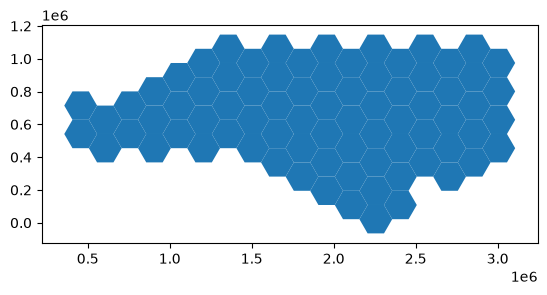

In [43]:
# Let's look at that heaxgon grid
grid.plot() 

In [45]:
def hexCountMap(ax, grid, counties):
    grid.plot(
        ax=ax,
        column="total",
        cmap="RdPu",
        edgecolor="white",
        linewidth=0.2,
        legend=True,
        legend_kwds={"label": "Number of observation records"}
    )

    nc_counties.boundary.plot(
        ax=ax,
        color="gray",
        linewidth=0.4
    )

    ax.set_title("GBIF observations per hexagon")
    ax.set_axis_off()
    return ax

In [46]:
from matplotlib.patches import Rectangle

def hexBivariateMap(ax, grid, counties):
    mapped = grid.copy()

    for name in ["Dionaea muscipula", "Sarracenia flava"]:
        values = mapped[name]
        median = values.loc[values > 0].median()

        mapped[name + "_class"] = np.select(
            [values == 0, values <= median],
            [0, 1],
            default=2
        )

    palette = np.array([
        ["#eeeeee", "#c5b5d8", "#80619e"],
        ["#e6b899", "#b992a8", "#785b82"],
        ["#cf763e", "#a35e63", "#63384f"]
    ])

    mapped["color"] = [
        palette[red, white]
        for red, white in zip(
            mapped["Dionaea muscipula"],
            mapped["Sarracenia flava"]
        )
    ]

    mapped.plot(
        ax=ax,
        color=mapped["color"],
        edgecolor="white",
        linewidth=0.2
    )

    nc_counties.boundary.plot(ax=ax, color="gray", linewidth=0.4)

    legend_ax = ax.inset_axes([0.05, 0.05, 0.18, 0.23])

    for red in range(3):
        for white in range(3):
            legend_ax.add_patch(
                Rectangle(
                    (white, red), 1, 1,
                    facecolor=palette[red, white],
                    edgecolor="white"
                )
            )

    legend_ax.set_xlim(0, 3)
    legend_ax.set_ylim(0, 3)
    legend_ax.set_aspect("equal")
    legend_ax.set_xticks([0.5, 1.5, 2.5])
    legend_ax.set_yticks([0.5, 1.5, 2.5])
    legend_ax.set_xticklabels(["Zero", "Lower", "Higher"], fontsize=7)
    legend_ax.set_yticklabels(["Zero", "Lower", "Higher"], fontsize=7)
    legend_ax.set_xlabel("White mulberry", fontsize=8)
    legend_ax.set_ylabel("Red mulberry", fontsize=8)
    legend_ax.tick_params(length=0)

    ax.set_title("Red and white mulberry observations")
    ax.set_axis_off()
    return ax

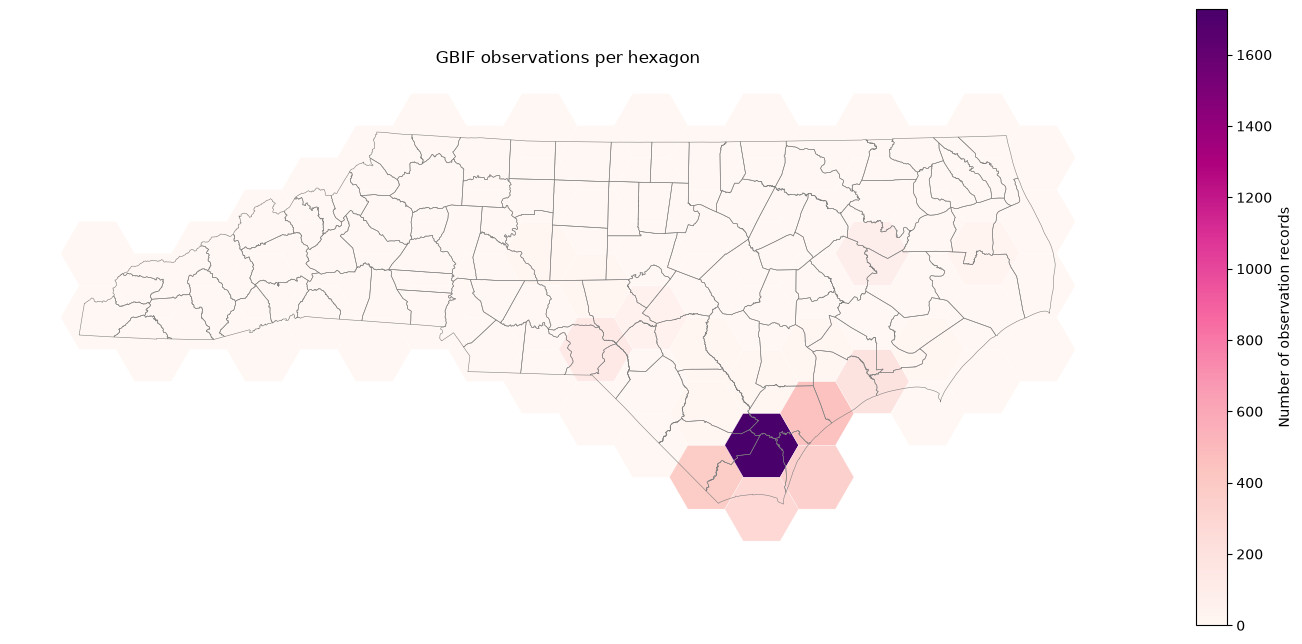

In [56]:
fig, ax = plt.subplots(
    figsize=(18, 8)
)

hexCountMap(ax, grid, states)

plt.show()